# Comparative Analysis of OB Transform
## 1. Introduction & Hypotheses
We examine how compactly the existing biorthogonal OB transform represents structured signals compared with real orthonormal Fourier, DCT-II and Ternary Haar. An OB advantage is not assumed.

Four hypotheses guide the experiment: ternary alignment helps OB; frequency bases better represent smooth periodic data; sample order affects hierarchical signal sparsity; sparse reconstruction can reduce noise. Dataset E is a positive control of the benchmark, not evidence of general superiority.

**Method:** each row is a signal. Coefficients are ranked by `abs(c[j]) * ||synthesis[j, :]||₂`, the L2 norm of an individual reconstruction component. This is not a globally optimal K-term approximation for a biorthogonal basis. All errors are measured in signal space. The energy-recovery proxy is `1 − relative_L2²`; it can be negative and is not a sum of OB coefficient energies.

## 2. Experiment Configuration
All adjustable parameters are in the next cell. Each class has 64 realizations distributed across subtypes; D_permuted contains paired permutations of D. Signals have unit RMS without mean subtraction, preserving the constant component.

Install the locked environment with `uv sync --frozen`. From the repository root run `uv run jupyter nbconvert --execute --to notebook --inplace --ExecutePreprocessor.timeout=1800 ob_transform_comparison.ipynb`. Versions and device details are printed below and recorded in `run_metadata.json`.

In [1]:
from pathlib import Path
import csv
import hashlib
import html
import importlib.metadata
import json
import os
import platform
import sys
import time
import zipfile

import matplotlib.pyplot as plt
import mlx.core as mx
import numpy as np
import scipy
from scipy import fft as spfft
from IPython.display import HTML, Markdown, display

CONFIG = {
    "seed": 42, "primary_n": 729, "extra_n": 2187, "run_extra": True,
    "validation_sizes": [27, 81], "realizations": 64,
    "fractions": [0.01, 0.02, 0.05, 0.10, 0.20, 0.40, 0.60, 1.0],
    "display_fraction": 0.10, "dtype": "float32", "ob_device": "gpu",
    "batch_size": 64, "snr_db": [0, 10, 20],
    "noise_types": ["Gaussian", "Uniform"], "control_atoms": 3,
    "timing_batch_sizes": [1, 64], "timing_warmup": 3, "timing_repeats": 9,
    "max_working_memory_mib": 1024, "output_dir": "ob_transform_comparison_results",
}
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "obf/core.py").exists())
sys.path.insert(0, str(ROOT))
from obf.core import OBMatrix
from ob import OBMatrixCalculator

OUT = ROOT / CONFIG["output_dir"]
OUT.mkdir(exist_ok=True)
DTYPE = np.dtype(CONFIG["dtype"])
METHODS = ["OB", "Fourier", "DCT-II", "Ternary Haar"]
COLORS = dict(zip(METHODS, ["#235789", "#a76b00", "#b24f36", "#637a32"]))
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.18, "figure.dpi": 110})

def rng_for(n, tag):
    return np.random.default_rng(np.random.SeedSequence([CONFIG["seed"], n, tag]))

def table(rows, columns=None, limit=30):
    if not rows:
        print("No rows")
        return
    columns = columns or list(rows[0])
    def fmt(v):
        return f"{v:.5g}" if isinstance(v, (float, np.floating)) else str(v)
    text = "<table><thead><tr>" + "".join(f"<th>{html.escape(c)}</th>" for c in columns) + "</tr></thead><tbody>"
    for row in rows[:limit]:
        text += "<tr>" + "".join(f"<td>{html.escape(fmt(row.get(c, '')))}</td>" for c in columns) + "</tr>"
    display(HTML(text + "</tbody></table>"))
    if len(rows) > limit:
        print(f"Showing {limit} of {len(rows)} rows; full data are exported to CSV.")

def save_csv(name, rows):
    if rows:
        with (OUT / name).open("w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=list(rows[0]))
            writer.writeheader(); writer.writerows(rows)

def show_figure(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

ENV = {"platform": platform.platform(), "python": platform.python_version(),
       "numpy": np.__version__, "scipy": scipy.__version__,
       "mlx": importlib.metadata.version("mlx"), "matplotlib": importlib.metadata.version("matplotlib"),
       "ob_device": str(getattr(mx, CONFIG["ob_device"])), "dtype": str(DTYPE),
       "baseline_backend": "SciPy/NumPy CPU, one FFT worker", "hardware": mx.device_info()}
print(json.dumps(ENV, indent=2))


{
  "platform": "macOS-27.2-arm64-arm-64bit-Mach-O",
  "python": "3.13.15",
  "numpy": "2.5.4",
  "scipy": "1.18.1",
  "mlx": "0.32.4",
  "matplotlib": "3.11.2",
  "ob_device": "DeviceType.gpu",
  "dtype": "float32",
  "baseline_backend": "SciPy/NumPy CPU, one FFT worker",
  "hardware": {
    "device_name": "Apple M4 Max",
    "max_recommended_working_set_size": 30150672384,
    "memory_size": 38654705664,
    "architecture": "applegpu_g16s",
    "max_buffer_length": 22613000192,
    "resource_limit": 499000
  }
}


### Asset audit and the recovered 243 matrix
The original file named `ob_mx_243.safetensors` contained 81×81 matrices. Publication preparation replaced it with the verified 243×243 int8 copy. Other original assets retain their values and storage types.

The MLX generator reproduces `ob.py` formulas using exact lookup tables indexed by ternary digit dot products modulo three. A separate reproducible 243 copy is written to `recovered_matrices/`. If the original local `.pt` files are present, their raw int8 storage is compared without unpickling. These redundant PyTorch files are not required or distributed. The main experiments use saved 729 and 2187 assets, not generated replacements.

In [2]:
ASSET_AUDIT = []
LOAD_TIMES = {}
for path in sorted((ROOT / "obf/matrices").glob("*.safetensors")):
    declared = int(path.stem.split("_")[-1])
    start = time.perf_counter()
    arrays = mx.load(str(path)); mx.eval(*arrays.values())
    elapsed = (time.perf_counter() - start) * 1000
    valid = all(k in arrays and arrays[k].shape == (declared, declared) for k in ["forward", "inverse"])
    ASSET_AUDIT.append({"file": path.name, "declared_n": declared,
                        "forward_shape": str(arrays["forward"].shape), "inverse_shape": str(arrays["inverse"].shape),
                        "dtype": str(arrays["forward"].dtype), "inverse_dtype": str(arrays["inverse"].dtype), "valid_shape": valid,
                        "load_ms": elapsed, "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
    LOAD_TIMES[declared] = elapsed

recovery_dir = OUT / "recovered_matrices"
recovery_dir.mkdir(exist_ok=True)
recovered_path = recovery_dir / "ob_mx_243.safetensors"
f243, b243 = OBMatrixCalculator.calculate_matrix(5)
for direction, generated in [("forward", f243), ("inverse", b243)]:
    path = ROOT / "obf/matrices" / f"ob_{direction}_5.pt"
    if path.exists():
        import pickletools
        with zipfile.ZipFile(path) as archive:
            names = archive.namelist()
            metadata = archive.read(next(k for k in names if k.endswith("/data.pkl")))
            operations = list(pickletools.genops(metadata))
            globals_used = [arg for op, arg, _ in operations if op.name == "GLOBAL"]
            assert globals_used == ["torch._utils _rebuild_tensor_v2", "torch CharStorage", "collections OrderedDict"]
            after_storage = next(i for i, (op, _, _) in enumerate(operations) if op.name == "BINPERSID")
            integers = [arg for op, arg, _ in operations[after_storage + 1:] if op.name in ("BININT", "BININT1", "BININT2")]
            assert integers == [0, 243, 243, 243, 1], integers
            assert archive.read(next(k for k in names if k.endswith("/byteorder"))) == b"little"
            raw = archive.read(next(k for k in names if k.endswith("/data/0")))
        assert len(raw) == 243 * 243
        assert np.array_equal(np.frombuffer(raw, dtype=np.int8).reshape(243, 243), np.asarray(generated))
        print(f"Generated {direction} matrix matches provided PT storage exactly.")
mx.save_safetensors(str(recovered_path), {"forward": f243, "inverse": b243})
table(ASSET_AUDIT, ["file", "declared_n", "forward_shape", "inverse_shape", "dtype", "valid_shape", "load_ms"])
save_csv("asset_audit.csv", ASSET_AUDIT)
print(f"Recovered int8 copy: {recovered_path.relative_to(ROOT)}")

estimated_extra_mib = (8 * CONFIG["extra_n"] ** 2 * 4 + 40 * CONFIG["realizations"] * CONFIG["extra_n"] * 4) / 2**20
extra_asset_ok = any(r["declared_n"] == CONFIG["extra_n"] and r["valid_shape"] for r in ASSET_AUDIT)
EXPERIMENT_SIZES = [CONFIG["primary_n"]]
if CONFIG["run_extra"] and extra_asset_ok and estimated_extra_mib <= CONFIG["max_working_memory_mib"]:
    EXPERIMENT_SIZES.append(CONFIG["extra_n"])
print(f"Experiment sizes: {EXPERIMENT_SIZES}; extra working-memory estimate: {estimated_extra_mib:.1f} MiB")


Generated forward matrix matches provided PT storage exactly.
Generated inverse matrix matches provided PT storage exactly.


file,declared_n,forward_shape,inverse_shape,dtype,valid_shape,load_ms
ob_mx_2187.safetensors,2187,"(2187, 2187)","(2187, 2187)",mlx.core.float32,True,2.163
ob_mx_243.safetensors,243,"(243, 243)","(243, 243)",mlx.core.int8,True,0.17783
ob_mx_27.safetensors,27,"(27, 27)","(27, 27)",mlx.core.float32,True,0.11596
ob_mx_3.safetensors,3,"(3, 3)","(3, 3)",mlx.core.float32,True,0.054292
ob_mx_729.safetensors,729,"(729, 729)","(729, 729)",mlx.core.float32,True,0.2895
ob_mx_81.safetensors,81,"(81, 81)","(81, 81)",mlx.core.float32,True,0.078625
ob_mx_9.safetensors,9,"(9, 9)","(9, 9)",mlx.core.float32,True,0.054584


Recovered int8 copy: ob_transform_comparison_results/recovered_matrices/ob_mx_243.safetensors
Experiment sizes: [729, 2187]; extra working-memory estimate: 167.3 MiB


## 3. Transform Implementations
The common `forward(X)` / `inverse(C)` interface returns real float32 arrays. OB uses the existing `obf.core.OBMatrix`: analysis is `X @ forward / N`; synthesis is `C @ inverse`.

Fourier uses exactly N real coefficients: DC followed by pairs `sqrt(2)·Re(FFT[k])`, `−sqrt(2)·Im(FFT[k])`. Odd N has no Nyquist component. Sine and cosine count as two independent real coefficients.

Ternary Haar recursively maps adjacent triples to an average and two details: `(a+b+c)/sqrt(3)`, `(a−b)/sqrt(2)`, `(a+b−2c)/sqrt(6)`. Averages are grouped again, producing a localized hierarchical basis.

Vilenkin–Chrestenson and Walsh–Hadamard remain extensions. Complex Vilenkin requires separate real-degree-of-freedom accounting; Walsh requires another dimension. Neither enters the main ranking.

In [3]:
class Transform:
    def __init__(self, name, n, forward, inverse, synthesis_norms=None):
        self.name, self.n = name, n
        self.forward, self.inverse = forward, inverse
        self.synthesis_norms = np.ones(n, dtype=DTYPE) if synthesis_norms is None else synthesis_norms
        self.backend = "NumPy/SciPy CPU"

class OBTransformAdapter:
    name = "OB"
    backend = "MLX"
    def __init__(self, n, matrices_dir=None, device=None):
        self.n = n
        self.device = device if device is not None else getattr(mx, CONFIG["ob_device"])
        self.core = OBMatrix(n, matrices_dir=str(matrices_dir or ROOT / "obf/matrices"))
        matrix = self.core._matrix["inverse"]
        # Row j is the synthesis function multiplied by coefficient j.
        self.synthesis_norms = np.linalg.norm(np.asarray(matrix).astype(np.float64), axis=1).astype(DTYPE)
    def forward(self, x):
        with mx.stream(self.device):
            y = self.core(mx.array(np.ascontiguousarray(x, dtype=DTYPE)))
            mx.eval(y)
            return np.array(y)
    def inverse(self, c):
        with mx.stream(self.device):
            y = self.core.inverse(mx.array(np.ascontiguousarray(c, dtype=DTYPE)))
            mx.eval(y)
            return np.array(y)

def fourier_forward(x):
    z = spfft.rfft(x, norm="ortho", axis=-1, workers=1)
    c = np.empty(x.shape, dtype=DTYPE)
    c[..., 0] = z[..., 0].real
    c[..., 1::2] = np.sqrt(2) * z[..., 1:].real
    c[..., 2::2] = -np.sqrt(2) * z[..., 1:].imag
    return c

def fourier_inverse(c):
    z = np.empty((*c.shape[:-1], c.shape[-1] // 2 + 1), dtype=np.complex64)
    z[..., 0] = c[..., 0]
    z[..., 1:] = (c[..., 1::2] - 1j * c[..., 2::2]) / np.sqrt(2)
    return spfft.irfft(z, n=c.shape[-1], norm="ortho", axis=-1, workers=1).astype(DTYPE)

def haar_forward(x):
    out = x.copy()
    m = x.shape[-1]
    while m > 1:
        q = m // 3
        triples = out[..., :m].reshape(*out.shape[:-1], q, 3).copy()
        a, b, c = triples[..., 0], triples[..., 1], triples[..., 2]
        out[..., :q] = (a + b + c) / np.sqrt(3)
        out[..., q:m] = np.stack(((a - b) / np.sqrt(2), (a + b - 2 * c) / np.sqrt(6)), axis=-1).reshape(*out.shape[:-1], 2 * q)
        m = q
    return out

def haar_inverse(c):
    out = c.copy()
    m = 3
    while m <= c.shape[-1]:
        q = m // 3
        average = out[..., :q].copy() / np.sqrt(3)
        details = out[..., q:m].reshape(*out.shape[:-1], q, 2).copy()
        d1, d2 = details[..., 0] / np.sqrt(2), details[..., 1] / np.sqrt(6)
        out[..., :m] = np.stack((average + d1 + d2, average - d1 + d2, average - 2 * d2), axis=-1).reshape(*out.shape[:-1], m)
        m *= 3
    return out

def make_transforms(n, matrices_dir=None):
    assert n % 2 == 1
    return {
        "OB": OBTransformAdapter(n, matrices_dir),
        "Fourier": Transform("Fourier", n, fourier_forward, fourier_inverse),
        "DCT-II": Transform("DCT-II", n,
            lambda x: spfft.dct(x, type=2, norm="ortho", workers=1).astype(DTYPE),
            lambda c: spfft.idct(c, type=2, norm="ortho", workers=1).astype(DTYPE)),
        "Ternary Haar": Transform("Ternary Haar", n, haar_forward, haar_inverse),
    }

def batched(function, x):
    b = CONFIG["batch_size"]
    return np.concatenate([function(x[i:i+b]) for i in range(0, len(x), b)], axis=0)

TRANSFORMS = {}


## 4. Mathematical Validation
Float32 tolerances: relative reconstruction error ≤3e−5; maximum matrix inverse residual ≤5e−5; relative Parseval and inner-product residuals for orthonormal methods ≤5e−6. At 27 and 81, orthonormality is also checked on explicit basis matrices; larger sizes use reproducible random vectors. OB is not treated as orthonormal or checked with Parseval.

Both OB matrix products are checked: `(forward/N) @ inverse` and `inverse @ (forward/N)`. Failed method/size combinations are excluded with reasons. K=N uses the same masking procedure as the benchmark.

In [4]:
def select_coefficients(c, transform, k, rule="contribution"):
    scores = np.abs(c) * (transform.synthesis_norms if rule == "contribution" else 1)
    order = np.argsort(-scores, axis=-1, kind="stable")
    selected = order[..., :k]
    masked = np.zeros_like(c)
    np.put_along_axis(masked, selected, np.take_along_axis(c, selected, axis=-1), axis=-1)
    return masked

VALIDATION, EXCLUSIONS = [], []
validation_sizes = sorted(set(CONFIG["validation_sizes"] + EXPERIMENT_SIZES + [243]))
for n in validation_sizes:
    models = make_transforms(n, recovery_dir if n == 243 else None)
    valid_models = {}
    rng = rng_for(n, 101)
    x = rng.normal(size=(16, n)).astype(DTYPE)
    const = np.ones((2, n), dtype=DTYPE)
    for name, transform in models.items():
        try:
            c = transform.forward(x)
            xr = transform.inverse(select_coefficients(c, transform, n))
            cc = transform.forward(const)
            const_rec = transform.inverse(cc)
            rel = float(np.max(np.linalg.norm(xr-x, axis=1) / np.linalg.norm(x, axis=1)))
            const_err = float(np.max(np.abs(const_rec-const)))
            assert c.shape == x.shape and c.dtype == DTYPE and xr.dtype == DTYPE
            assert np.isrealobj(c) and np.isrealobj(xr) and np.all(np.isfinite(xr))
            assert rel < 3e-5 and const_err < 3e-5
            norm_error = float("nan"); gram_error = float("nan"); identity_error = float("nan")
            condition_number = float("nan")
            synth_offdiag = float("nan"); generator_equal = "not applicable"
            if name == "OB":
                assert all(v.dtype in (mx.int8, mx.float32) and np.isfinite(np.asarray(v)).all() for v in transform.core._matrix.values())
                a = transform.core._matrix["forward"].astype(mx.float32) / n
                b = transform.core._matrix["inverse"].astype(mx.float32)
                p, q, g = a @ b, b @ a, b @ b.T
                mx.eval(p, q, g)
                identity_error = max(float(np.max(np.abs(np.asarray(p)-np.eye(n)))), float(np.max(np.abs(np.asarray(q)-np.eye(n)))))
                assert identity_error < 5e-5
                if n <= 243: condition_number = float(np.linalg.cond(np.asarray(a).astype(np.float64)))
                gn = np.asarray(g); synth_offdiag = float(np.max(np.abs(gn - np.diag(np.diag(gn)))))
                gf, gi = OBMatrixCalculator.calculate_matrix(round(np.log(n)/np.log(3)))
                generator_equal = bool(np.array_equal(np.asarray(gf), np.asarray(a * n).round()) and np.array_equal(np.asarray(gi), np.asarray(b)))
                assert generator_equal
            else:
                original_energy = np.sum(x.astype(np.float64)**2, axis=1)
                norm_error = float(np.max(np.abs(np.sum(c.astype(np.float64)**2, axis=1)/original_energy-1)))
                ip_error = float(abs(np.dot(c[0], c[1])-np.dot(x[0], x[1])) / (np.linalg.norm(x[0])*np.linalg.norm(x[1])))
                assert norm_error < 5e-6 and ip_error < 5e-6
                if n in CONFIG["validation_sizes"]:
                    analysis = transform.forward(np.eye(n, dtype=DTYPE))
                    gram_error = float(np.max(np.abs(analysis.T @ analysis - np.eye(n))))
                    assert gram_error < 5e-6
            VALIDATION.append({"n": n, "method": name, "roundtrip_rel_max": rel,
                "constant_abs_max": const_err, "constant_active": int(np.sum(abs(cc[0]) > np.max(abs(cc[0]))*1e-5)),
                "parseval_rel_max": norm_error, "small_gram_abs_max": gram_error,
                "ob_identity_abs_max": identity_error, "synthesis_offdiag_max": synth_offdiag,
                "generator_exact_match": generator_equal, "analysis_condition_small_n": condition_number, "status": "passed"})
            valid_models[name] = transform
        except (AssertionError, ValueError, RuntimeError) as exc:
            EXCLUSIONS.append({"n": n, "method": name, "reason": repr(exc)})
    TRANSFORMS[n] = valid_models
for n in EXPERIMENT_SIZES:
    assert set(TRANSFORMS[n]) == set(METHODS), f"Core methods failed validation for {n}: {EXCLUSIONS}"
table(VALIDATION, ["n", "method", "roundtrip_rel_max", "constant_abs_max", "constant_active", "parseval_rel_max", "ob_identity_abs_max", "status"], limit=30)
save_csv("validation.csv", VALIDATION)
print(f"Excluded methods: {EXCLUSIONS}")


n,method,roundtrip_rel_max,constant_abs_max,constant_active,parseval_rel_max,ob_identity_abs_max,status
27,OB,2.0311e-07,0,1,nan,2.3842e-07,passed
27,Fourier,1.9043e-07,0,1,1.3308e-07,nan,passed
27,DCT-II,2.0523e-07,0,1,1.9289e-07,nan,passed
27,Ternary Haar,7.7881e-08,1.7881e-07,1,6.9032e-08,nan,passed
81,OB,2.8956e-07,0,1,nan,4.7684e-07,passed
81,Fourier,1.7347e-07,0,1,9.0291e-08,nan,passed
81,DCT-II,1.7756e-07,0,1,6.6509e-08,nan,passed
81,Ternary Haar,6.5494e-08,1.7881e-07,1,3.4298e-08,nan,passed
243,OB,3.5888e-07,5.9605e-08,1,nan,4.7684e-07,passed
243,Fourier,2.2514e-07,5.9605e-08,1,1.5631e-07,nan,passed


Excluded methods: []


## 5. Synthetic Data Generation
A: thirds/ninths/twenty-sevenths, arbitrary segments, narrow pulses and multiple steps. B: FFT-bin sinusoid, harmonics, off-bin sinusoid, linear/nonlinear trends and Gaussian pulses. C: Gaussian/Uniform white noise, AR(1) with coefficient 0.95 after warm-up, and a low-frequency random process. D: depths 1–4 with independent level changes in recursive ternary segments. D_permuted applies one shared random permutation to every paired signal at each N, preserving values and pairwise distances.

E: 16 combinations of three synthesis atoms from each basis. Individual component norms are equalized before summation. A–D have equal realization counts; subtype results are also saved.

In [5]:
def unit_rms(x):
    return (x / max(float(np.sqrt(np.mean(np.asarray(x, dtype=np.float64)**2))), 1e-12)).astype(DTYPE)

def generate_data(n, transforms):
    rng = rng_for(n, 201)
    count = CONFIG["realizations"]
    time_axis = np.arange(n) / n
    centered = 2*time_axis - 1
    arrays, variants = {}, {}
    names_a = ["ternary_aligned", "arbitrary_segments", "narrow_pulses", "multiple_steps"]
    names_b = ["bin_sine", "harmonic_sum", "off_grid_sine", "linear_trend", "smooth_trend", "smooth_pulse"]
    names_c = ["Gaussian_white", "Uniform_white", "AR1", "low_frequency_process"]
    for dataset, names in [("A", names_a), ("B", names_b), ("C", names_c), ("D", [f"depth_{j}" for j in range(1,5)])]:
        rows, labels = [], []
        for i in range(count):
            variant = names[i % len(names)]
            x = np.zeros(n)
            if dataset == "A":
                if variant == "ternary_aligned":
                    segments = int(rng.choice([3, 9, 27]))
                    x = np.repeat(rng.normal(size=segments), n//segments)
                elif variant in ["arbitrary_segments", "multiple_steps"]:
                    segments = int(rng.integers(3, 13 if variant == "arbitrary_segments" else 8))
                    bounds = np.r_[0, np.sort(rng.choice(np.arange(1,n), segments-1, replace=False)), n]
                    levels = rng.normal(size=segments)
                    if variant == "multiple_steps": levels = np.cumsum(levels)
                    for j in range(segments): x[bounds[j]:bounds[j+1]] = levels[j]
                else:
                    for _ in range(int(rng.integers(1,5))):
                        width = int(rng.integers(1, max(2,n//30)))
                        start = int(rng.integers(0,n-width+1))
                        x[start:start+width] += rng.choice([-1,1])*rng.uniform(0.5,2)
            elif dataset == "B":
                frequency = int(rng.integers(1, max(3,n//12)))
                phase = rng.uniform(-np.pi,np.pi)
                if variant == "bin_sine": x = np.sin(2*np.pi*frequency*time_axis + phase)
                elif variant == "off_grid_sine": x = np.sin(2*np.pi*(frequency+rng.uniform(.15,.85))*time_axis+phase)
                elif variant == "harmonic_sum":
                    fundamental = int(rng.integers(1,7))
                    x = sum(rng.uniform(.5,1.5)/j*np.sin(2*np.pi*fundamental*j*time_axis+rng.uniform(-np.pi,np.pi)) for j in range(1,5))
                elif variant == "linear_trend": x = rng.normal()+rng.choice([-1,1])*centered
                elif variant == "smooth_trend": x = rng.normal()+rng.normal()*centered+rng.normal()*centered**2+rng.normal()*centered**3
                else: x = np.exp(-.5*((time_axis-rng.uniform(.2,.8))/rng.uniform(.03,.15))**2)
            elif dataset == "C":
                if variant == "Gaussian_white": x = rng.normal(size=n)
                elif variant == "Uniform_white": x = rng.uniform(-np.sqrt(3),np.sqrt(3),size=n)
                elif variant == "AR1":
                    innovations = rng.normal(size=n+256)
                    for j in range(1,n+256): innovations[j] += .95*innovations[j-1]
                    x = innovations[256:]
                else:
                    raw = rng.normal(size=n)
                    freqs = np.arange(n//2+1)
                    spectrum = spfft.rfft(raw)*np.exp(-.5*(freqs/8)**2)
                    x = spfft.irfft(spectrum,n=n)
            else:
                depth = int(variant.split("_")[-1])
                x[:] = rng.normal()
                for level in range(1,depth+1):
                    for block in np.array_split(np.arange(n),3**level):
                        if rng.random() < .75:
                            x[block] += rng.normal() * .7**(level-1)
            rows.append(unit_rms(x)); labels.append(variant)
        arrays[dataset], variants[dataset] = np.stack(rows), np.array(labels)
    permutation = rng.permutation(n)
    arrays["D_permuted"] = arrays["D"][:,permutation].copy()
    variants["D_permuted"] = variants["D"].copy()
    rows, labels = [], []
    for i in range(count):
        name = METHODS[i % len(METHODS)]
        transform = transforms[name]
        c = np.zeros((1,n),dtype=DTYPE)
        positions = rng.choice(np.arange(1,n), CONFIG["control_atoms"], replace=False)
        c[0,positions] = rng.normal(size=len(positions))/transform.synthesis_norms[positions]
        rows.append(unit_rms(transform.inverse(c)[0])); labels.append(name)
    arrays["E"], variants["E"] = np.stack(rows), np.array(labels)
    return arrays, variants

DATA = {n: generate_data(n, TRANSFORMS[n]) for n in EXPERIMENT_SIZES}
table([{"n":n,"class":d,"shape":str(x.shape),"subtypes":", ".join(np.unique(v[d]))} for n,(a,v) in DATA.items() for d,x in a.items()], limit=20)


n,class,shape,subtypes
729,A,"(64, 729)","arbitrary_segments, multiple_steps, narrow_pulses, ternary_aligned"
729,B,"(64, 729)","bin_sine, harmonic_sum, linear_trend, off_grid_sine, smooth_pulse, smooth_trend"
729,C,"(64, 729)","AR1, Gaussian_white, Uniform_white, low_frequency_process"
729,D,"(64, 729)","depth_1, depth_2, depth_3, depth_4"
729,D_permuted,"(64, 729)","depth_1, depth_2, depth_3, depth_4"
729,E,"(64, 729)","DCT-II, Fourier, OB, Ternary Haar"
2187,A,"(64, 2187)","arbitrary_segments, multiple_steps, narrow_pulses, ternary_aligned"
2187,B,"(64, 2187)","bin_sine, harmonic_sum, linear_trend, off_grid_sine, smooth_pulse, smooth_trend"
2187,C,"(64, 2187)","AR1, Gaussian_white, Uniform_white, low_frequency_process"
2187,D,"(64, 2187)","depth_1, depth_2, depth_3, depth_4"


## 6. Transform Coefficient Analysis
We compare sorted norms of individual synthesis contributions. Their squared sum is not interpreted as OB signal energy. Each output feature is standardized separately for marginal-shape comparisons. Gaussian-like coordinate marginals do not establish joint normality or independence.

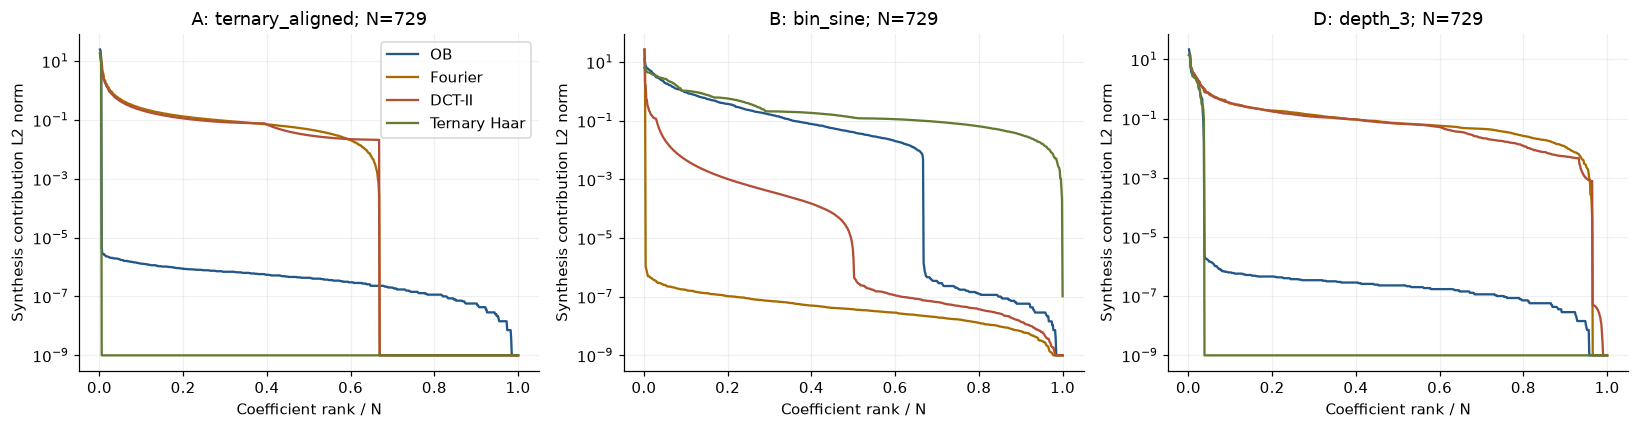

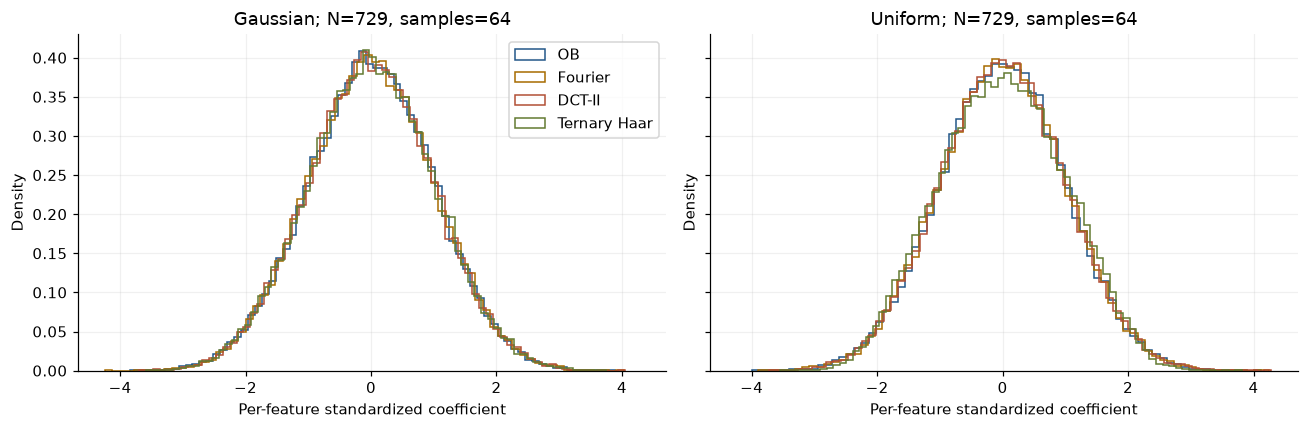

In [6]:
n = CONFIG["primary_n"]
models = TRANSFORMS[n]
a, variants = DATA[n]
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, dataset, subtype in zip(axes, ["A","B","D"], ["ternary_aligned","bin_sine","depth_3"]):
    index = int(np.flatnonzero(variants[dataset] == subtype)[0])
    x = a[dataset][index:index+1]
    for name,t in models.items():
        contributions = np.sort(np.abs(t.forward(x)[0])*t.synthesis_norms)[::-1]
        ax.semilogy(np.arange(1,n+1)/n, np.maximum(contributions,1e-9), label=name,color=COLORS[name])
    ax.set(title=f"{dataset}: {subtype}; N={n}",xlabel="Coefficient rank / N",ylabel="Synthesis contribution L2 norm")
axes[0].legend(); fig.tight_layout(); show_figure(fig,"coefficient_contributions")

rng = rng_for(n,301)
distributions = {"Gaussian":rng.normal(size=(CONFIG["realizations"],n)).astype(DTYPE),
                 "Uniform":rng.uniform(-np.sqrt(3),np.sqrt(3),size=(CONFIG["realizations"],n)).astype(DTYPE)}
fig, axes = plt.subplots(1,2,figsize=(12,4),sharex=True,sharey=True)
MARGINALS=[]
for ax,(label,x) in zip(axes,distributions.items()):
    for name,t in models.items():
        c=t.forward(x); z=(c-c.mean(axis=0))/np.maximum(c.std(axis=0),1e-12)
        ax.hist(z.ravel(),bins=70,density=True,histtype="step",label=name,color=COLORS[name])
        MARGINALS.append({"n":n,"input":label,"method":name,"median_excess_kurtosis":float(np.median(np.mean(z**4,axis=0)-3))})
    ax.set(title=f"{label}; N={n}, samples={len(x)}",xlabel="Per-feature standardized coefficient",ylabel="Density")
axes[0].legend(); fig.tight_layout(); show_figure(fig,"marginal_distributions")
save_csv("marginal_shapes.csv",MARGINALS)


## 7. Sparse Reconstruction Benchmark
K is rounded upward: `max(1, ceil(fraction·N))`; tables report actual fractions. Statistics are means and standard deviations across realizations. NRMSE relative to input RMS equals relative L2 mathematically; both columns are retained explicitly.

Boundary errors use samples within two positions of A jumps (difference >10% of the largest jump) and known D hierarchy boundaries. They are undefined for other types. Naive OB selection by `abs(c)` is a separate diagnostic, outside the main ranking.

In [7]:
def metrics(x, reconstructed, boundary=None):
    delta = reconstructed.astype(np.float64)-x.astype(np.float64)
    error2 = np.sum(delta**2,axis=1)
    signal2 = np.sum(x.astype(np.float64)**2,axis=1)
    relative = np.sqrt(error2/np.maximum(signal2,1e-30))
    result = {"relative_l2":relative,"rmse":np.sqrt(error2/x.shape[1]),"nrmse_l2":relative,
              "energy_recovery_score":1-error2/np.maximum(signal2,1e-30),
              "max_abs":np.max(np.abs(delta),axis=1)}
    if boundary is not None:
        result["boundary_rmse"] = np.sqrt(np.sum(delta**2*boundary,axis=1)/np.maximum(boundary.sum(axis=1),1))
    return result

def boundary_mask(x,dataset,labels):
    if dataset not in ["A","D"]: return None
    mask=np.zeros(x.shape,dtype=bool); n=x.shape[1]
    for i,row in enumerate(x):
        if dataset=="A":
            dif=np.abs(np.diff(row)); points=np.flatnonzero(dif>max(1e-8,float(dif.max())*.1))+1
        else:
            depth=int(labels[i].split("_")[-1]); points=np.arange(1,3**depth)*n//(3**depth)
        for p in points: mask[i,max(0,p-2):min(n,p+3)] = True
    return mask

def aggregate(rows, base, values, labels=None):
    groups=[("ALL",np.ones(len(next(iter(values.values()))),dtype=bool))]
    if labels is not None: groups += [(str(label), labels==label) for label in np.unique(labels)]
    for group,mask in groups:
        row={**base,"subtype":group,"count":int(mask.sum())}
        for key,v in values.items():
            selected=v[mask]; row[key+"_mean"]=float(np.mean(selected)); row[key+"_std"]=float(np.std(selected,ddof=1)) if len(selected)>1 else 0.0
        rows.append(row)

SPARSE=[]; RAW_OB=[]; CONTROL_CHECKS=[]; PAIRED_ORDER=[]
for n in EXPERIMENT_SIZES:
    arrays,labels=DATA[n]; models=TRANSFORMS[n]
    cached_d={}
    for dataset,x in arrays.items():
        boundary=boundary_mask(x,dataset,labels[dataset])
        for name,t in models.items():
            coefficients=batched(t.forward,x)
            for fraction in CONFIG["fractions"]:
                k=max(1,int(np.ceil(fraction*n)))
                reconstructed=batched(t.inverse,select_coefficients(coefficients,t,k))
                values=metrics(x,reconstructed,boundary)
                aggregate(SPARSE,{"n":n,"dataset":dataset,"method":name,"k":k,"fraction":k/n,"requested_fraction":fraction},values,labels[dataset])
                if fraction==CONFIG["display_fraction"] and dataset in ["D","D_permuted"]:
                    cached_d[(dataset,name)]=values["relative_l2"]
                if name=="OB" and dataset!="E":
                    naive=batched(t.inverse,select_coefficients(coefficients,t,k,rule="magnitude"))
                    aggregate(RAW_OB,{"n":n,"dataset":dataset,"method":"OB_abs","k":k,"fraction":k/n,"requested_fraction":fraction},metrics(x,naive))
            if dataset=="E":
                k=CONFIG["control_atoms"]
                xr=batched(t.inverse,select_coefficients(coefficients,t,k))
                for origin in METHODS:
                    mask=labels["E"]==origin
                    error=metrics(x[mask],xr[mask])["relative_l2"]
                    CONTROL_CHECKS.append({"n":n,"source_basis":origin,"method":name,"k":k,"mean_error":float(error.mean()),"std_error":float(error.std(ddof=1))})
                    if origin==name: assert float(error.max()) < 3e-5, (n,origin,error.max())
    for name in METHODS:
        change=cached_d[("D_permuted",name)]-cached_d[("D",name)]
        PAIRED_ORDER.append({"n":n,"method":name,"permutation_error_delta_mean":float(change.mean()),"paired_std":float(change.std(ddof=1))})
    print(f"Completed sparse reconstruction for N={n}.")
save_csv("sparse_summary.csv",SPARSE);save_csv("ob_magnitude_diagnostic.csv",RAW_OB)
save_csv("basis_controls.csv",CONTROL_CHECKS);save_csv("paired_permutation.csv",PAIRED_ORDER)


Completed sparse reconstruction for N=729.


Completed sparse reconstruction for N=2187.


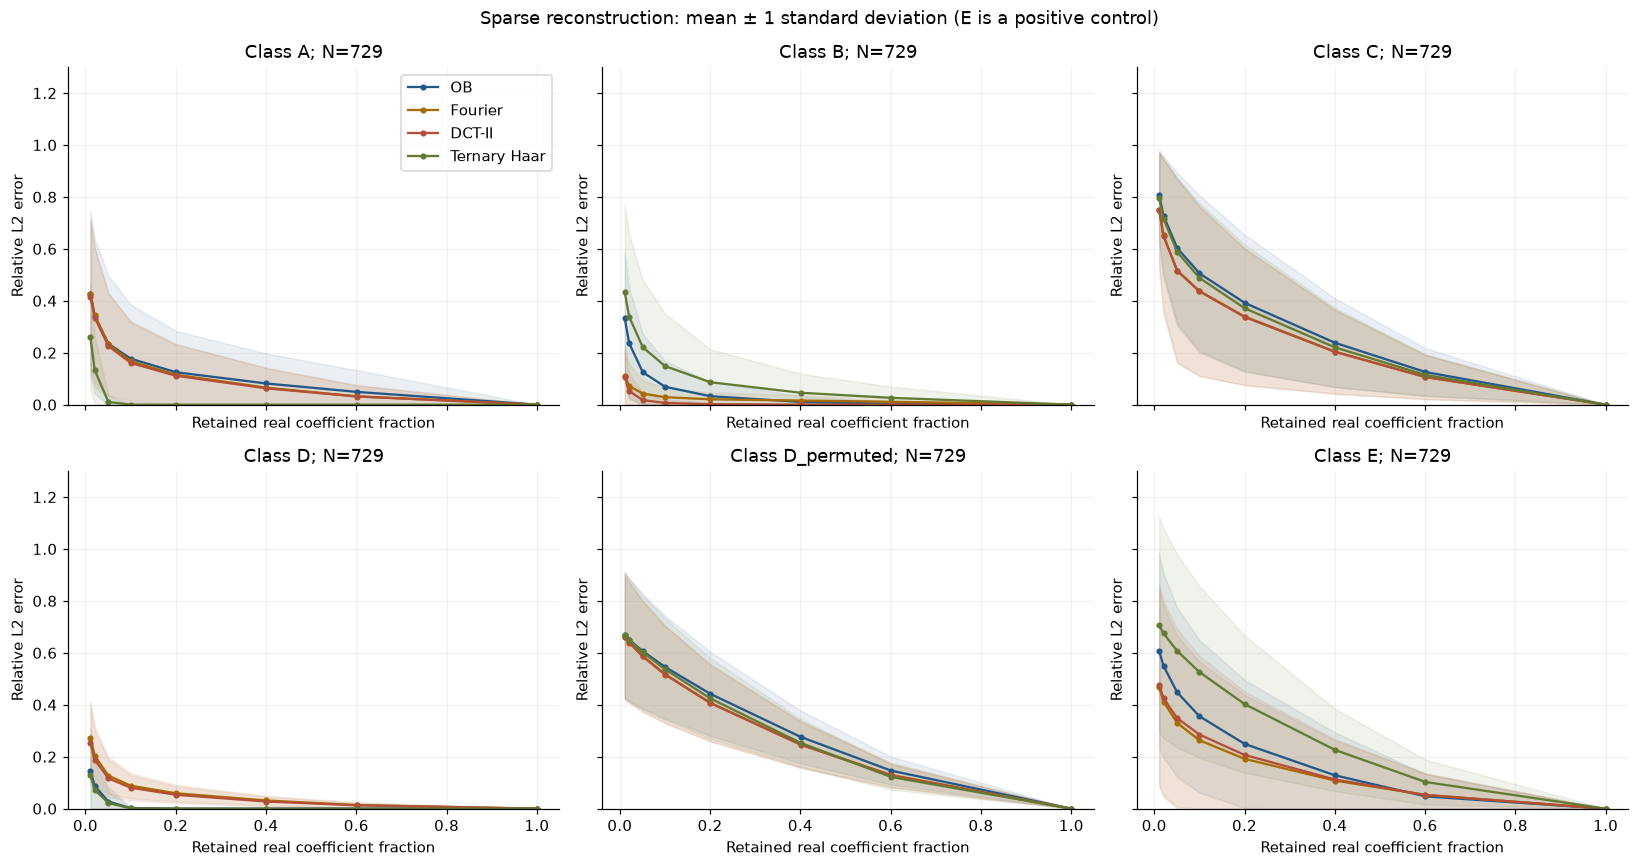

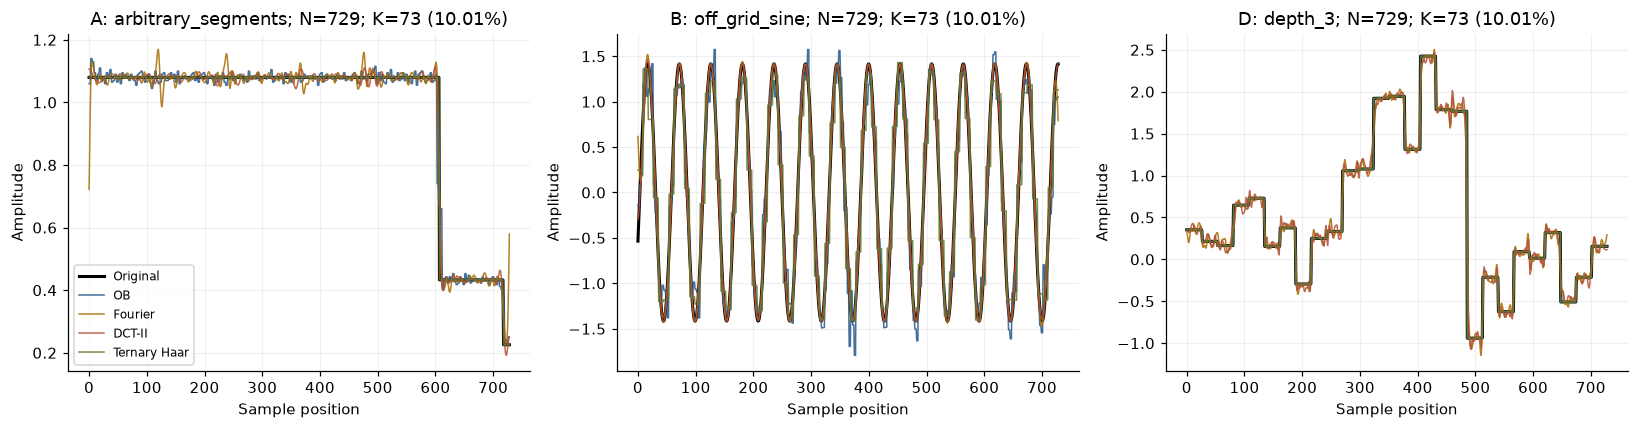

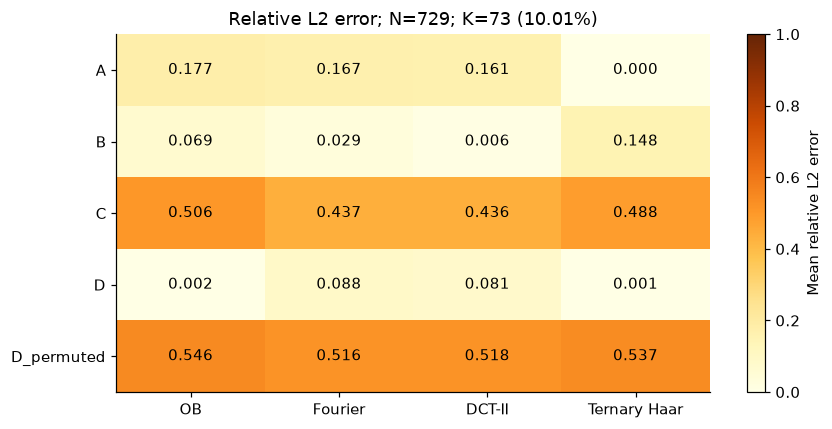

dataset,method,k,fraction,relative_l2_mean,relative_l2_std,rmse_mean,energy_recovery_score_mean
A,OB,73,0.10014,0.17712,0.20865,0.17712,0.92577
A,Fourier,73,0.10014,0.16739,0.1545,0.16739,0.94848
A,DCT-II,73,0.10014,0.16074,0.15722,0.16074,0.94983
A,Ternary Haar,73,0.10014,9.4736e-08,4.7902e-08,9.4736e-08,1
B,OB,73,0.10014,0.068957,0.098814,0.068957,0.98563
B,Fourier,73,0.10014,0.028742,0.035461,0.028742,0.99794
B,DCT-II,73,0.10014,0.0064859,0.012484,0.0064859,0.9998
B,Ternary Haar,73,0.10014,0.14844,0.20242,0.14844,0.93763
C,OB,73,0.10014,0.50561,0.30039,0.50561,0.65554
C,Fourier,73,0.10014,0.43733,0.328,0.43733,0.70284


In [8]:
n=CONFIG["primary_n"]
fig,axes=plt.subplots(2,3,figsize=(15,8),sharex=True,sharey=True)
for ax,dataset in zip(axes.ravel(),["A","B","C","D","D_permuted","E"]):
    for name in METHODS:
        rows=sorted([r for r in SPARSE if r["n"]==n and r["dataset"]==dataset and r["method"]==name and r["subtype"]=="ALL"],key=lambda r:r["fraction"])
        xx=np.array([r["fraction"] for r in rows]); yy=np.array([r["relative_l2_mean"] for r in rows]); sd=np.array([r["relative_l2_std"] for r in rows])
        ax.plot(xx,yy,label=name,color=COLORS[name],marker=".")
        ax.fill_between(xx,np.maximum(0,yy-sd),yy+sd,color=COLORS[name],alpha=.09)
    ax.set(title=f"Class {dataset}; N={n}",xlabel="Retained real coefficient fraction",ylabel="Relative L2 error")
    ax.set_ylim(0,1.3)
axes[0,0].legend();fig.suptitle("Sparse reconstruction: mean ± 1 standard deviation (E is a positive control)")
fig.tight_layout();show_figure(fig,"sparse_curves")

n=CONFIG["primary_n"]; fraction=CONFIG["display_fraction"]; k=int(np.ceil(n*fraction))
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,dataset,variant in zip(axes,["A","B","D"],["arbitrary_segments","off_grid_sine","depth_3"]):
    a,labels=DATA[n];i=int(np.flatnonzero(labels[dataset]==variant)[0]);x=a[dataset][i:i+1]
    ax.plot(x[0],color="black",lw=2,label="Original")
    for name,t in TRANSFORMS[n].items():
        restored=t.inverse(select_coefficients(t.forward(x),t,k))
        ax.plot(restored[0],label=name,color=COLORS[name],lw=1,alpha=.85)
    ax.set(title=f"{dataset}: {variant}; N={n}; K={k} ({k/n:.2%})",xlabel="Sample position",ylabel="Amplitude")
axes[0].legend(fontsize=8);fig.tight_layout();show_figure(fig,"example_reconstructions")

MAIN_CLASSES=["A","B","C","D","D_permuted"]
main_rows=[r for r in SPARSE if r["n"]==n and r["subtype"]=="ALL" and r["requested_fraction"]==fraction and r["dataset"] in MAIN_CLASSES]
heat=np.array([[next(r["relative_l2_mean"] for r in main_rows if r["dataset"]==d and r["method"]==m) for m in METHODS] for d in MAIN_CLASSES])
fig,ax=plt.subplots(figsize=(8,4))
im=ax.imshow(heat,cmap="YlOrBr",vmin=0,vmax=max(1,float(heat.max())),aspect="auto")
ax.set_xticks(range(4),METHODS);ax.set_yticks(range(len(MAIN_CLASSES)),MAIN_CLASSES)
for i in range(len(MAIN_CLASSES)):
    for j in range(4):ax.text(j,i,f"{heat[i,j]:.3f}",ha="center",va="center",color="black")
ax.grid(False)
ax.set_title(f"Relative L2 error; N={n}; K={k} ({k/n:.2%})")
fig.colorbar(im,ax=ax,label="Mean relative L2 error");fig.tight_layout();show_figure(fig,"class_error_heatmap")
table(main_rows,["dataset","method","k","fraction","relative_l2_mean","relative_l2_std","rmse_mean","energy_recovery_score_mean"],limit=24)


## 8. Noise Filtering Experiment
Independent Gaussian and Uniform noise is added to clean A, B and D at 0, 10 and 20 dB. Scaling uses theoretical variance and nominal SNR, without normalizing each realized noise vector; this preserves independent samples and their distribution. Realized SNR is measured separately and its mean and standard deviation are saved with the unfiltered baseline. All methods receive identical noisy inputs. Selection uses **only noisy coefficients**, ranked by the same contribution norm. Clean signals are used only for error evaluation.

All K values are shown without selecting the best on test data; the summary uses the predetermined 10%. Hard top-K is not an optimal noise filter. At 100%, error should match the original noise.

Completed both noise families for N=729.


Completed both noise families for N=2187.


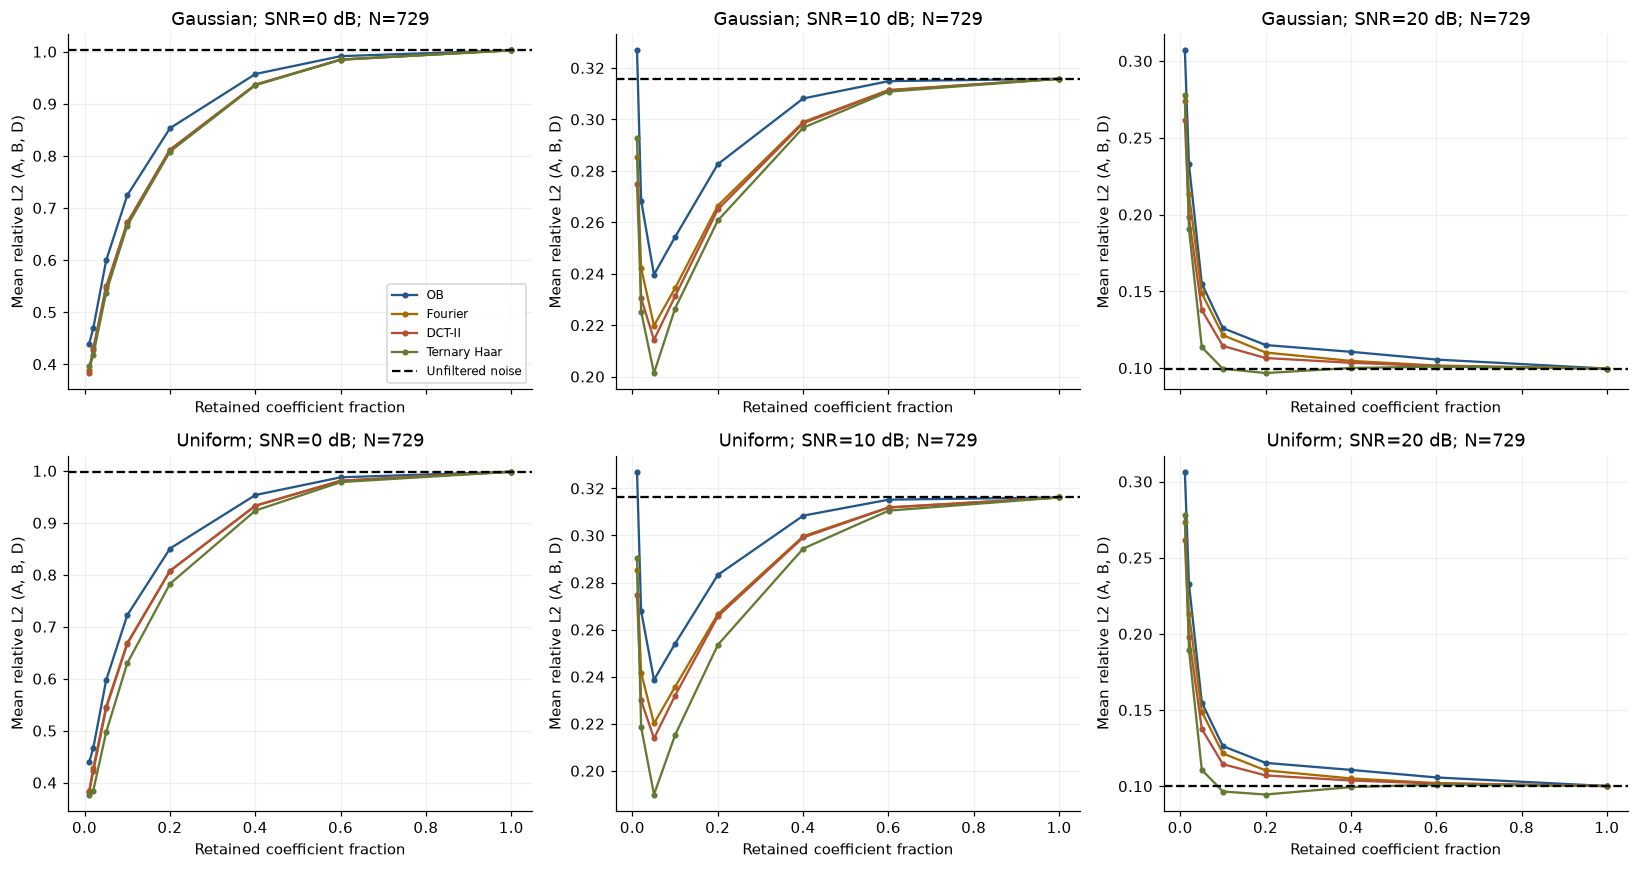

Noise plots show means; pooled standard deviations are displayed in the final summary and exported to CSV.


In [9]:
NOISE=[]; NOISE_BASELINE=[]
for n in EXPERIMENT_SIZES:
    arrays,labels=DATA[n]
    for noise_index,noise_type in enumerate(CONFIG["noise_types"]):
        for snr in CONFIG["snr_db"]:
            rng=rng_for(n,401+noise_index*100+snr)
            for dataset in ["A","B","D"]:
                clean=arrays[dataset]
                raw=rng.normal(size=clean.shape) if noise_type=="Gaussian" else rng.uniform(-np.sqrt(3),np.sqrt(3),size=clean.shape)
                raw=raw*np.sqrt(np.mean(clean.astype(np.float64)**2,axis=1,keepdims=True))*10**(-snr/20)
                noisy=(clean+raw).astype(DTYPE)
                baseline_values=metrics(clean,noisy)
                baseline_values["realized_snr_db"]=-20*np.log10(baseline_values["relative_l2"])
                aggregate(NOISE_BASELINE,{"n":n,"dataset":dataset,"noise":noise_type,"snr_db":snr},baseline_values)
                for name,t in TRANSFORMS[n].items():
                    coefficients=batched(t.forward,noisy)
                    for fraction in CONFIG["fractions"]:
                        k=max(1,int(np.ceil(fraction*n)))
                        denoised=batched(t.inverse,select_coefficients(coefficients,t,k))
                        values=metrics(clean,denoised)
                        if k==n: assert np.max(np.abs(values["relative_l2"]-baseline_values["relative_l2"])) < 3e-5
                        aggregate(NOISE,{"n":n,"dataset":dataset,"noise":noise_type,"snr_db":snr,"method":name,"k":k,"fraction":k/n,"requested_fraction":fraction},values)
    print(f"Completed both noise families for N={n}.")
save_csv("noise_summary.csv",NOISE);save_csv("noise_unfiltered.csv",NOISE_BASELINE)

n=CONFIG["primary_n"]
fig,axes=plt.subplots(2,3,figsize=(15,8),sharex=True)
for row,noise_type in enumerate(CONFIG["noise_types"]):
    for col,snr in enumerate(CONFIG["snr_db"]):
        ax=axes[row,col]
        for name in METHODS:
            means=[];fractions=[];spreads=[]
            for f in CONFIG["fractions"]:
                rows=[r for r in NOISE if r["n"]==n and r["noise"]==noise_type and r["snr_db"]==snr and r["method"]==name and r["requested_fraction"]==f]
                grand=float(np.mean([r["relative_l2_mean"] for r in rows]))
                total=sum(r["count"] for r in rows)
                variance=sum((r["count"]-1)*r["relative_l2_std"]**2+r["count"]*(r["relative_l2_mean"]-grand)**2 for r in rows)/(total-1)
                means.append(grand);spreads.append(np.sqrt(variance));fractions.append(rows[0]["fraction"])
            ax.plot(fractions,means,label=name,color=COLORS[name],marker=".")
        observed_baseline=np.mean([r["relative_l2_mean"] for r in NOISE_BASELINE if r["n"]==n and r["noise"]==noise_type and r["snr_db"]==snr])
        ax.axhline(observed_baseline,color="black",ls="--",label="Unfiltered noise")
        ax.set(title=f"{noise_type}; SNR={snr} dB; N={n}",xlabel="Retained coefficient fraction",ylabel="Mean relative L2 (A, B, D)")
axes[0,0].legend(fontsize=8);fig.tight_layout();show_figure(fig,"noise_filtering_curves")
print("Noise plots show means; pooled standard deviations are displayed in the final summary and exported to CSV.")


## 9. Computational Performance
Asset loading is timed separately; the OS cache is not cleared. Resident MLX GPU and CPU arrays are timed with `mx.eval()` before stopping the clock. A separate NumPy-facing OB wrapper includes transfers. Baselines use CPU, with one SciPy FFT/DCT worker. GPU/CPU timings are not presented as algorithmic complexity comparisons.

After warm-up, median and interquartile range are reported. Forward+inverse is timed as a composition, not a sum of medians. Memory is a lower bound for matrices and three batch×N float32 arrays, not peak RSS; allocator/FFT workspace and temporary casts are excluded. Dense OB costs O(batch·N²), FFT/DCT O(batch·N log N), and local Haar O(batch·N).

In [10]:
def measure(function, synchronize=None):
    for _ in range(CONFIG["timing_warmup"]):
        result=function()
        if synchronize: synchronize(result)
    durations=[]
    for _ in range(CONFIG["timing_repeats"]):
        start=time.perf_counter();result=function()
        if synchronize: synchronize(result)
        durations.append((time.perf_counter()-start)*1000)
    return float(np.median(durations)),float(np.quantile(durations,.75)-np.quantile(durations,.25))

PERFORMANCE=[]
for n in EXPERIMENT_SIZES:
    for batch in CONFIG["timing_batch_sizes"]:
        x=rng_for(n,501+batch).normal(size=(batch,n)).astype(DTYPE)
        for name,t in TRANSFORMS[n].items():
            c=t.forward(x)
            operations={"forward":lambda t=t:t.forward(x),"inverse":lambda t=t,c=c:t.inverse(c),"pair":lambda t=t:t.inverse(t.forward(x))}
            for operation,function in operations.items():
                median,iqr=measure(function)
                PERFORMANCE.append({"n":n,"batch":batch,"method":name,"backend":f"MLX {CONFIG['ob_device'].upper()} + host transfer" if name=="OB" else "CPU NumPy/SciPy",
                    "operation":operation,"median_ms":median,"iqr_ms":iqr,"dtype":str(DTYPE),
                    "matrix_mib":2*n*n*4/2**20 if name=="OB" else 0.,"three_arrays_mib":3*batch*n*4/2**20})
        core=TRANSFORMS[n]["OB"].core
        for device_name in ["cpu","gpu"]:
            device=getattr(mx,device_name)
            with mx.stream(device):
                resident_x=mx.array(x);resident_c=core(resident_x);mx.eval(resident_x,resident_c)
                operations={"forward":lambda:core(resident_x),"inverse":lambda:core.inverse(resident_c),"pair":lambda:core.inverse(core(resident_x))}
                for operation,function in operations.items():
                    median,iqr=measure(function,lambda result:mx.eval(result))
                    PERFORMANCE.append({"n":n,"batch":batch,"method":"OB","backend":f"MLX {device_name.upper()} resident",
                        "operation":operation,"median_ms":median,"iqr_ms":iqr,"dtype":str(DTYPE),
                        "matrix_mib":2*n*n*4/2**20,"three_arrays_mib":3*batch*n*4/2**20})
save_csv("performance.csv",PERFORMANCE)
table([r for r in PERFORMANCE if r["n"]==CONFIG["primary_n"] and r["batch"]==64],
      ["method","backend","operation","median_ms","iqr_ms","matrix_mib","three_arrays_mib"],limit=25)


method,backend,operation,median_ms,iqr_ms,matrix_mib,three_arrays_mib
OB,MLX GPU + host transfer,forward,0.16412,0.009791,4.0546,0.53394
OB,MLX GPU + host transfer,inverse,0.15642,0.003125,4.0546,0.53394
OB,MLX GPU + host transfer,pair,0.31196,0.011834,4.0546,0.53394
Fourier,CPU NumPy/SciPy,forward,0.067334,0.006208,0,0.53394
Fourier,CPU NumPy/SciPy,inverse,0.12342,0.003833,0,0.53394
Fourier,CPU NumPy/SciPy,pair,0.19308,0.003459,0,0.53394
DCT-II,CPU NumPy/SciPy,forward,0.045917,0.00016601,0,0.53394
DCT-II,CPU NumPy/SciPy,inverse,0.047,0.001167,0,0.53394
DCT-II,CPU NumPy/SciPy,pair,0.092541,0.00016601,0,0.53394
Ternary Haar,CPU NumPy/SciPy,forward,0.14188,0.00091601,0,0.53394


## 10. Results & Conclusions
The next cell generates summaries. The primary slice uses the predetermined 10% coefficient fraction; E controls are separate. Mean relative L2 is also integrated over the actual retained fractions using trapezoids, normalized by interval width. This describes the curve and is not statistical proof of superiority.

Ternary alignment comparisons concern specific A subtypes and D depths, not all ternary signals. Between-realization variability includes parameter and subtype differences; confidence intervals and significance tests are not claimed.

n,dataset,OB,Fourier,DCT-II,Ternary Haar,lowest_mean_method
729,A,0.17712,0.16739,0.16074,9.4736e-08,Ternary Haar
729,B,0.068957,0.028742,0.0064859,0.14844,DCT-II
729,C,0.50561,0.43733,0.43636,0.48803,DCT-II
729,D,0.002013,0.088328,0.080596,0.0011883,Ternary Haar
729,D_permuted,0.54553,0.51647,0.51751,0.53667,Fourier
729,E,0.35565,0.26353,0.2852,0.52593,not ranked (positive control)
2187,A,0.099665,0.093355,0.088445,9.4051e-08,Ternary Haar
2187,B,0.042108,0.015645,0.0041662,0.14839,DCT-II
2187,C,0.48868,0.43916,0.43879,0.47218,DCT-II
2187,D,6.0734e-06,0.053626,0.047805,1.1689e-07,Ternary Haar


dataset,subtype,method,relative_l2_mean,relative_l2_std
A,arbitrary_segments,OB,0.14791,0.064284
A,multiple_steps,OB,0.06403,0.034519
A,narrow_pulses,OB,0.49655,0.14379
A,ternary_aligned,OB,2.2934e-06,1.1645e-06
A,arbitrary_segments,Fourier,0.11041,0.047098
A,multiple_steps,Fourier,0.055801,0.025232
A,narrow_pulses,Fourier,0.38079,0.15692
A,ternary_aligned,Fourier,0.12255,0.072867
A,arbitrary_segments,DCT-II,0.10533,0.047553
A,multiple_steps,DCT-II,0.04373,0.022052


n,method,permutation_error_delta_mean,paired_std
729,OB,0.54352,0.19718
729,Fourier,0.42814,0.15602
729,DCT-II,0.43691,0.15832
729,Ternary Haar,0.53548,0.19502
2187,OB,0.58236,0.19668
2187,Fourier,0.4938,0.16716
2187,DCT-II,0.50134,0.17174
2187,Ternary Haar,0.56426,0.1901


n,noise,snr_db,unfiltered,OB,Fourier,DCT-II,Ternary Haar
729,Gaussian,0,1.0026,0.7242 ± 0.059,0.6722 ± 0.0443,0.671 ± 0.0448,0.6659 ± 0.0521
729,Gaussian,10,0.31579,0.2543 ± 0.0971,0.2344 ± 0.0712,0.2312 ± 0.0719,0.2265 ± 0.0913
729,Gaussian,20,0.099681,0.126 ± 0.133,0.1214 ± 0.0984,0.1144 ± 0.0996,0.0996 ± 0.12
729,Uniform,0,0.99833,0.7221 ± 0.0539,0.6683 ± 0.041,0.6671 ± 0.0418,0.6298 ± 0.0541
729,Uniform,10,0.31615,0.254 ± 0.0968,0.2357 ± 0.0712,0.2319 ± 0.0716,0.2151 ± 0.0938
729,Uniform,20,0.10009,0.1263 ± 0.132,0.1215 ± 0.0985,0.1145 ± 0.0996,0.0965 ± 0.121
2187,Gaussian,0,0.99981,0.715 ± 0.025,0.6641 ± 0.0178,0.6629 ± 0.0176,0.67 ± 0.0507
2187,Gaussian,10,0.31605,0.235 ± 0.0444,0.2178 ± 0.0295,0.2169 ± 0.0294,0.2336 ± 0.0936
2187,Gaussian,20,0.099899,0.0978 ± 0.0725,0.08891 ± 0.0476,0.08591 ± 0.048,0.1047 ± 0.126
2187,Uniform,0,0.99952,0.7161 ± 0.0255,0.6642 ± 0.0171,0.6638 ± 0.0172,0.6343 ± 0.0479


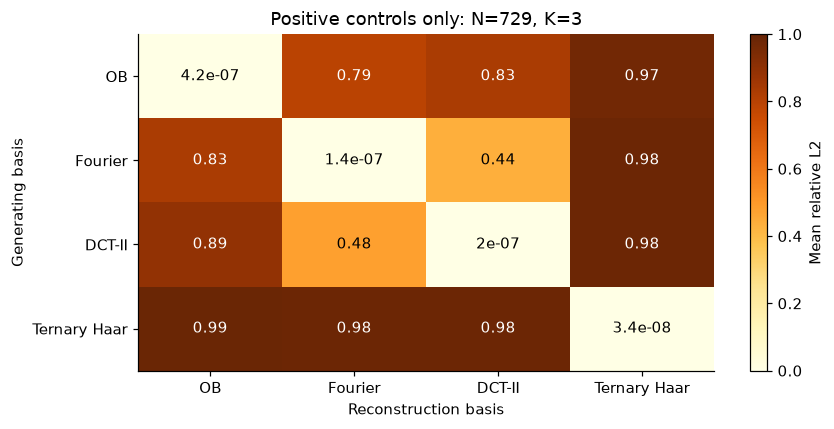

n,dataset,OB_contribution_error,OB_magnitude_error
729,A,0.17712,0.17712
729,B,0.068957,0.068957
729,C,0.50561,0.50561
729,D,0.002013,0.002013
729,D_permuted,0.54553,0.54558
2187,A,0.099665,0.099671
2187,B,0.042108,0.042108
2187,C,0.48868,0.4887
2187,D,6.0734e-06,6.0734e-06
2187,D_permuted,0.58236,0.58238


Exported compact summaries and figures to ob_transform_comparison_results


n,subtype,method,k,relative_l2_mean,relative_l2_std
729,linear_trend,OB,15,1.9287e-07,1.236e-07
729,smooth_trend,OB,15,0.041968,0.017799
729,linear_trend,Fourier,15,0.13758,0.049018
729,smooth_trend,Fourier,15,0.13647,0.093978
729,linear_trend,DCT-II,15,0.0018383,0.00066346
729,smooth_trend,DCT-II,15,0.010212,0.0062814
729,linear_trend,Ternary Haar,15,0.055324,0.019468
729,smooth_trend,Ternary Haar,15,0.062844,0.023445
2187,linear_trend,OB,44,2.3908e-07,1.5015e-07
2187,smooth_trend,OB,44,0.0062782,0.006734


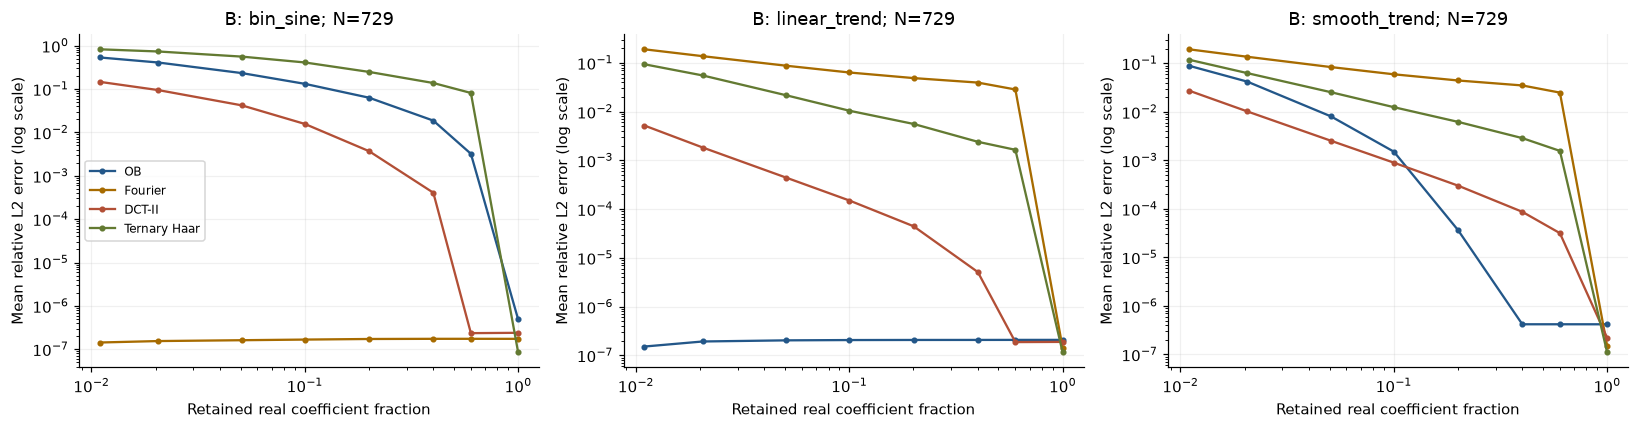

n,active_coefficients,fraction,relative_l2_float64
729,7,0.0096022,1.9566e-16
2187,8,0.003658,2.7295e-16


In [11]:
SUMMARY=[]; CURVE_SUMMARY=[]
for n in EXPERIMENT_SIZES:
    for dataset in ["A","B","C","D","D_permuted","E"]:
        row={"n":n,"dataset":dataset}
        for name in METHODS:
            r=next(r for r in SPARSE if r["n"]==n and r["dataset"]==dataset and r["method"]==name and r["subtype"]=="ALL" and r["requested_fraction"]==CONFIG["display_fraction"])
            row[name]=r["relative_l2_mean"]
            series=sorted([r for r in SPARSE if r["n"]==n and r["dataset"]==dataset and r["method"]==name and r["subtype"]=="ALL"],key=lambda r:r["fraction"])
            xx=np.array([r["fraction"] for r in series]);yy=np.array([r["relative_l2_mean"] for r in series])
            CURVE_SUMMARY.append({"n":n,"dataset":dataset,"method":name,"integrated_relative_error":float(np.trapezoid(yy,xx)/(xx[-1]-xx[0]))})
        row["lowest_mean_method"]="not ranked (positive control)" if dataset=="E" else min(METHODS,key=lambda m:row[m]);SUMMARY.append(row)
table(SUMMARY,limit=20)
save_csv("main_summary.csv",SUMMARY);save_csv("integrated_curves.csv",CURVE_SUMMARY)

table([r for r in SPARSE if r["n"]==CONFIG["primary_n"] and r["dataset"] in ["A","D"] and r["subtype"]!="ALL" and r["requested_fraction"]==CONFIG["display_fraction"]],
      ["dataset","subtype","method","relative_l2_mean","relative_l2_std"],limit=40)
table(PAIRED_ORDER)

NOISE_FIXED=[]
for n in EXPERIMENT_SIZES:
    for noise_type in CONFIG["noise_types"]:
        for snr in CONFIG["snr_db"]:
            row={"n":n,"noise":noise_type,"snr_db":snr,"unfiltered":float(np.mean([r["relative_l2_mean"] for r in NOISE_BASELINE if r["n"]==n and r["noise"]==noise_type and r["snr_db"]==snr]))}
            for name in METHODS:
                rows=[r for r in NOISE if r["n"]==n and r["method"]==name and r["noise"]==noise_type and r["snr_db"]==snr and r["requested_fraction"]==CONFIG["display_fraction"]]
                grand=float(np.mean([r["relative_l2_mean"] for r in rows]));row[name]=grand
                total=sum(r["count"] for r in rows)
                row[name+"_std"]=float(np.sqrt(sum((r["count"]-1)*r["relative_l2_std"]**2+r["count"]*(r["relative_l2_mean"]-grand)**2 for r in rows)/(total-1)))
            NOISE_FIXED.append(row)
table([{**{key:r[key] for key in ["n","noise","snr_db","unfiltered"]}, **{name:f"{r[name]:.4g} ± {r[name + '_std']:.3g}" for name in METHODS}} for r in NOISE_FIXED],limit=15);save_csv("noise_fixed_fraction.csv",NOISE_FIXED)

n=CONFIG["primary_n"]
control_heat=np.array([[next(r["mean_error"] for r in CONTROL_CHECKS if r["n"]==n and r["source_basis"]==source and r["method"]==name) for name in METHODS] for source in METHODS])
fig,ax=plt.subplots(figsize=(8,4))
im=ax.imshow(control_heat,aspect="auto",cmap="YlOrBr",vmin=0,vmax=max(1,float(control_heat.max())))
ax.set_xticks(range(4),METHODS);ax.set_yticks(range(4),METHODS);ax.set(xlabel="Reconstruction basis",ylabel="Generating basis",title=f"Positive controls only: N={n}, K={CONFIG['control_atoms']}")
for i in range(4):
    for j in range(4):ax.text(j,i,f"{control_heat[i,j]:.2g}",ha="center",va="center",color="white" if control_heat[i,j]>.55 else "black")
ax.grid(False)
fig.colorbar(im,ax=ax,label="Mean relative L2");fig.tight_layout();show_figure(fig,"positive_controls")

DIAGNOSTICS=[]
for n in EXPERIMENT_SIZES:
    for dataset in MAIN_CLASSES:
        weighted=next(r for r in SPARSE if r["n"]==n and r["dataset"]==dataset and r["method"]=="OB" and r["subtype"]=="ALL" and r["requested_fraction"]==CONFIG["display_fraction"])
        naive=next(r for r in RAW_OB if r["n"]==n and r["dataset"]==dataset and r["requested_fraction"]==CONFIG["display_fraction"])
        DIAGNOSTICS.append({"n":n,"dataset":dataset,"OB_contribution_error":weighted["relative_l2_mean"],"OB_magnitude_error":naive["relative_l2_mean"]})
table(DIAGNOSTICS);save_csv("selection_diagnostic.csv",DIAGNOSTICS)
metadata={"config":CONFIG,"environment":ENV,"experiment_sizes":EXPERIMENT_SIZES,"extra_memory_estimate_mib":estimated_extra_mib,
          "excluded_assets":[r["file"] for r in ASSET_AUDIT if not r["valid_shape"]],"excluded_methods":EXCLUSIONS,
          "sources":{"core_sha256":hashlib.sha256((ROOT/'obf/core.py').read_bytes()).hexdigest(),
                     "generator_sha256":hashlib.sha256((ROOT/'ob.py').read_bytes()).hexdigest()}}
(OUT/"run_metadata.json").write_text(json.dumps(metadata,indent=2))
print(f"Exported compact summaries and figures to {OUT.relative_to(ROOT)}")


TREND_ROWS=[r for r in SPARSE if r["dataset"]=="B" and r["subtype"] in ["linear_trend","smooth_trend"] and r["requested_fraction"]==0.02]
table(TREND_ROWS,["n","subtype","method","k","relative_l2_mean","relative_l2_std"],limit=20)
save_csv("trend_diagnostic.csv",TREND_ROWS)
fig,axes=plt.subplots(1,3,figsize=(15,4),sharex=True)
for ax,subtype in zip(axes,["bin_sine","linear_trend","smooth_trend"]):
    for name in METHODS:
        rows=sorted([r for r in SPARSE if r["n"]==CONFIG["primary_n"] and r["dataset"]=="B" and r["subtype"]==subtype and r["method"]==name],key=lambda r:r["fraction"])
        ax.loglog([r["fraction"] for r in rows],[max(r["relative_l2_mean"],1e-8) for r in rows],label=name,color=COLORS[name],marker=".")
    ax.set(title=f"B: {subtype}; N={CONFIG['primary_n']}",xlabel="Retained real coefficient fraction",ylabel="Mean relative L2 error (log scale)")
axes[0].legend(fontsize=8);fig.tight_layout();show_figure(fig,"smooth_subtype_curves")


# Independent float64 diagnostic, separate from the float32 benchmark.
AFFINE_PRECISION=[]
for dimension in EXPERIMENT_SIZES:
    saved=mx.load(str(ROOT / "obf/matrices" / f"ob_mx_{dimension}.safetensors"))
    f64=np.asarray(saved["forward"]).astype(np.float64)
    b64=np.asarray(saved["inverse"]).astype(np.float64)
    ramp=.37+np.linspace(-1,1,dimension)
    ramp/=np.sqrt(np.mean(ramp*ramp))
    c64=ramp@f64/dimension
    support=np.flatnonzero(abs(c64)>max(abs(c64))*1e-10)
    retained=np.zeros_like(c64);retained[support]=c64[support]
    error=float(np.linalg.norm(retained@b64-ramp)/np.linalg.norm(ramp))
    AFFINE_PRECISION.append({"n":dimension,"active_coefficients":len(support),"fraction":len(support)/dimension,"relative_l2_float64":error})
    assert error<1e-12
    del f64,b64
save_csv("affine_precision_control.csv",AFFINE_PRECISION)
table(AFFINE_PRECISION)


### Interpretation of the executed run
Seed=42, float32, N=729 and 2187. If configuration changes, check numerical statements against regenerated summaries.

**Experimental observations.** Neither basis wins for every structure. At N=729, K=73 (10.01%), mean OB relative L2 errors are 0.177 (A), 0.0690 (B), 0.506 (C), and 0.00201 (D). Haar is best for A/D, DCT for B/C. The class-level pattern remains at N=2187. These are descriptive means, not significance tests.

1. **Linear trends.** At N=729, K=15 (2.06%), OB error is approximately 1.93e−7, versus 0.00184 for DCT, 0.138 for Fourier and 0.0553 for Haar. Trends at N=2187 also reconstruct near numerical precision with few coefficients. For a smooth polynomial trend at N=2187, K=219, OB gives 9.15e−6 versus DCT 1.87e−4. Independent float64 affine diagnostics find 7 active coefficients at N=729 and 8 at N=2187, with error below 1e−12. This effect is not float32 rounding. These signals are defined by formulas, not synthesized from OB coefficients; the narrow advantage does not establish superiority on smooth signals generally.
2. **Ternary alignment.** For aligned A boundaries, OB error at K=73 is about 2.3e−6, versus 0.148 for arbitrary boundaries and 0.497 for narrow pulses. Haar reconstructs these A variants nearly exactly at this K. In D, OB error grows from about 3e−6 at depth 1 to 0.00804 at depth 4. Permuting D increases OB error from 0.00201 to 0.546; order matters. Haar is also permutation-sensitive.
3. **Basis comparisons.** OB represents ternary levels and linear trends compactly; Haar localizes jumps better; DCT is better on average for the smooth mixture; Fourier fits bin-aligned periodic sinusoids. E controls pass: every basis recovers its own K=3 combinations with errors around 1e−7–1e−6. The E mixture must not be used as a ranking.
4. **Denoising.** At N=729, Gaussian SNR=10 dB and fixed 10%, average A/B/D OB error decreases from 0.316 unfiltered to 0.254. Haar gives 0.226 and DCT 0.231. At 20 dB, OB worsens this aggregate: 0.126 versus 0.100 unfiltered, although D improves. At N=2187 and 20 dB, OB averages about 0.098 while DCT gives about 0.086. Utility depends on class, SNR and K; a special OB denoising advantage is not established.
5. **Normalization and stability.** Ranking accounts for synthesis norms and errors are in signal space. At 10%, naive OB selection makes little difference. Trend sparsity is not explained by a global scale factor; compatibility between basis and signal structure remains the explanation. Maximum random OB round-trip errors are about 5.3e−7 at 729 and 1.0e−6 at 2187. Analysis condition numbers at 27/81/243 are close to sqrt(3); larger matrices were not separately checked by SVD.
6. **Cost and ML/AI hypotheses.** Timings distinguish CPU/GPU and transfers. Dense OB has no general computational advantage over DCT. Int8 reduces asset storage, while ordinary application casts weights to float32. Ordered trend/ternary data merit narrow further investigation; fixed feature extraction needs target-data experiments. No neural-network advantage was measured.

**Limitations.** One seed, 64 realizations per class, mixed subtypes, and one hard top-K policy. Within-class variability is substantial; small differences need additional seeds. Sizes use independent samples, so differences cannot be attributed only to N. Synthetic hierarchies favor localized ternary Haar and OB components. K counts real coefficients, not bits: indices, quantization and entropy coding are omitted. Memory is a lower bound, not peak RSS. Vilenkin–Chrestenson and Walsh remain extensions. The historical malformed 243 asset was recovered as a separate int8 copy, matching the supplied local `.pt` storage; publication also installs that verified copy as the standard 243 asset. Mathematical transform code is unchanged by publication preparation.